# Análisis de conductores y registros semanales

## Descripción de las tablas

**`drivers`** (34 filas, una por conductor)

| Variable | Descripción |
|---|---|
| `driverId` | Identificador del conductor |
| `name` | Nombre del conductor |
| `ssn` | Número de identificación personal (dato sensible, no se usa en el análisis) |
| `location` | Dirección |
| `certified` | Si el conductor está certificado (Y/N) |
| `wage-plan` | Esquema de pago: por horas (`hours`) o por millas (`miles`) |

**`timesheet`** (1.768 filas, una por conductor y semana)

| Variable | Descripción |
|---|---|
| `driverId` | Conductor al que pertenece el registro |
| `week` | Semana del año (1 a 52) |
| `hours-logged` | Horas registradas en la semana |
| `miles-logged` | Millas registradas en la semana |

## Llave de relación

La llave es `driverId`. Es única en `drivers` y se repite 52 veces en `timesheet`, por lo que la relación es de uno a muchos.

## Plan de análisis

1. Revisar la calidad de los datos: nulos, duplicados y semanas con 0 horas y 0 millas.
2. Resumir por conductor: promedios, sumas, mínimos y máximos.
3. Comparar cada semana contra el promedio de horas del propio conductor.
4. Unir los totales con los nombres de `drivers` para poder interpretarlos.
5. Identificar a los conductores con más millas y representarlos en un gráfico.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import FuncFormatter


def ubicar(nombre):
    base = Path.cwd().resolve()
    for carpeta in [base, *base.parents[:2]]:
        coincidencias = sorted(carpeta.rglob(nombre), key=lambda ruta: len(ruta.parts))
        if coincidencias:
            return coincidencias[0]
    raise FileNotFoundError(f"No encontré {nombre} cerca de {base}")


drivers = pd.read_csv(ubicar("drivers.csv"))
timesheet = pd.read_csv(ubicar("timesheet.csv"))

print(drivers.shape, timesheet.shape)
drivers.head()

(34, 6) (1768, 4)


,driverId,name,ssn,location,certified,wage-plan
0,10,George Vetticaden,621011971,244-4532 Nulla Rd.,N,miles
1,11,Jamie Engesser,262112338,366-4125 Ac Street,N,miles
2,12,Paul Coddin,198041975,Ap #622-957 Risus. Street,Y,hours
3,13,Joe Niemiec,139907145,2071 Hendrerit. Ave,Y,hours
4,14,Adis Cesir,820812209,Ap #810-1228 In St.,Y,hours


In [3]:
timesheet.head()

,driverId,week,hours-logged,miles-logged
0,10,1,70,3300
1,10,2,70,3300
2,10,3,60,2800
3,10,4,70,3100
4,10,5,70,3200


In [4]:
print("Nulos en drivers:", drivers.isna().sum().sum())
print("Nulos en timesheet:", timesheet.isna().sum().sum())
print("driverId único en drivers:", drivers["driverId"].is_unique)
print("Conductores de timesheet que no están en drivers:", set(timesheet["driverId"]) - set(drivers["driverId"]))
print("Semanas por conductor:", timesheet.groupby("driverId").size().unique())
print("Registros con 0 horas y 0 millas:", ((timesheet["hours-logged"] == 0) & (timesheet["miles-logged"] == 0)).sum())

Nulos en drivers: 0
Nulos en timesheet: 0
driverId único en drivers: True
Conductores de timesheet que no están en drivers: set()
Semanas por conductor: [52]
Registros con 0 horas y 0 millas: 11


## Promedio de horas y millas por conductor

In [5]:
promedios = (
    timesheet.groupby("driverId")[["hours-logged", "miles-logged"]]
    .mean()
    .reset_index()
)
promedios

,driverId,hours-logged,miles-logged
0,10,62.153846,2829.807692
1,11,70.038462,3448.076923
2,12,50.750000,2614.653846
3,13,52.442308,2579.346154
4,14,53.480769,2627.384615
5,15,52.576923,2668.269231
6,16,52.807692,2638.557692
7,17,51.942308,2615.230769
8,18,51.038462,2650.653846
9,19,52.653846,2653.230769


## Tabla `timesheet_with_means`

In [6]:
timesheet_with_means = timesheet.copy()
timesheet_with_means["mean_hours-logged"] = (
    timesheet_with_means.groupby("driverId")["hours-logged"].transform("mean")
)
timesheet_with_means.head()

,driverId,week,hours-logged,miles-logged,mean_hours-logged
0,10,1,70,3300,62.153846
1,10,2,70,3300,62.153846
2,10,3,60,2800,62.153846
3,10,4,70,3100,62.153846
4,10,5,70,3200,62.153846


## Tabla `timesheet_below`

In [7]:
timesheet_below = timesheet_with_means[
    timesheet_with_means["hours-logged"] < timesheet_with_means["mean_hours-logged"]
]
print(timesheet_below.shape)
timesheet_below.head()

(824, 5)


,driverId,week,hours-logged,miles-logged,mean_hours-logged
2,10,3,60,2800,62.153846
9,10,10,50,2500,62.153846
19,10,20,30,1200,62.153846
20,10,21,50,2500,62.153846
25,10,26,60,2600,62.153846


## Tabla `sum_timesheet`

In [8]:
sum_timesheet = (
    timesheet.groupby("driverId")[["hours-logged", "miles-logged"]]
    .sum()
    .reset_index()
)
sum_timesheet

,driverId,hours-logged,miles-logged
0,10,3232,147150
1,11,3642,179300
2,12,2639,135962
3,13,2727,134126
4,14,2781,136624
5,15,2734,138750
6,16,2746,137205
7,17,2701,135992
8,18,2654,137834
9,19,2738,137968


## Tabla `min_max_timesheet`

In [9]:
min_max_timesheet = (
    timesheet.groupby("driverId")["hours-logged"]
    .agg(**{"min_hours-logged": "min", "max_hours-logged": "max"})
    .reset_index()
)
min_max_timesheet

,driverId,min_hours-logged,max_hours-logged
0,10,0,76
1,11,0,92
2,12,0,60
3,13,10,60
4,14,45,60
5,15,45,60
6,16,45,60
7,17,20,60
8,18,45,60
9,19,45,60


## Tabla `summary`

In [10]:
summary = sum_timesheet.merge(drivers[["driverId", "name"]], on="driverId")
summary.to_csv("summary.csv", index=False)
summary

,driverId,hours-logged,miles-logged,name
0,10,3232,147150,George Vetticaden
1,11,3642,179300,Jamie Engesser
2,12,2639,135962,Paul Coddin
3,13,2727,134126,Joe Niemiec
4,14,2781,136624,Adis Cesir
5,15,2734,138750,Rohit Bakshi
6,16,2746,137205,Tom McCuch
7,17,2701,135992,Eric Mizell
8,18,2654,137834,Grant Liu
9,19,2738,137968,Ajay Singh


## Tabla `top10`

In [11]:
top10 = (
    summary.sort_values("miles-logged", ascending=False)
    .head(10)
    .reset_index(drop=True)
)
top10

,driverId,hours-logged,miles-logged,name
0,11,3642,179300,Jamie Engesser
1,10,3232,147150,George Vetticaden
2,33,2759,139285,Sridhara Sabbella
3,25,2723,139180,Jean-Philippe Playe
4,39,2745,138788,David Kaiser
5,15,2734,138750,Rohit Bakshi
6,35,2728,138727,Emil Siemes
7,21,2751,138719,Jeff Markham
8,41,2723,138407,Greg Phillips
9,29,2760,138255,Teddy Choi


## Gráfico de los 10 conductores con más millas

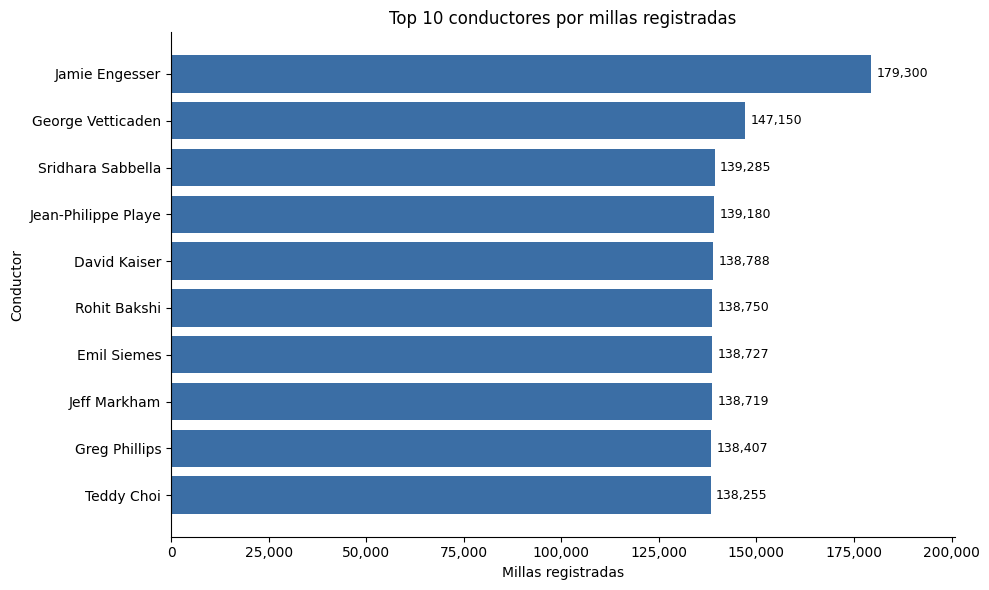

In [12]:
fig, ax = plt.subplots(figsize=(10, 6))
barras = ax.barh(top10["name"], top10["miles-logged"], color="#3b6ea5")
ax.invert_yaxis()
ax.set_xlabel("Millas registradas")
ax.set_ylabel("Conductor")
ax.set_title("Top 10 conductores por millas registradas")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.bar_label(barras, labels=[f"{v:,}" for v in top10["miles-logged"]], padding=4, fontsize=9)
ax.set_xlim(0, top10["miles-logged"].max() * 1.12)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("top10_drivers.png", dpi=150)
plt.show()

## Conclusiones

- Los conductores 10 y 11 son los únicos no certificados y con plan por millas, y son los que más millas y horas acumulan.
- Del tercer al décimo lugar las diferencias son muy pequeñas, por lo que ese tramo del ranking es casi un empate.
- Hay semanas con 0 horas y 0 millas, sobre todo en la semana 52. Se conservaron tal como vienen en los datos y por eso bajan algunos promedios.